<a href="https://colab.research.google.com/github/jesuscarpio5/Analisis-deportivo/blob/main/05_informe_postpartido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install mplsoccer statsbombpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mplsoccer]


In [3]:
from google.colab import drive
import pandas as pd, numpy as np, textwrap
import matplotlib.pyplot as plt
from mplsoccer import Pitch
import warnings
warnings.filterwarnings("ignore")

drive.mount("/content/drive")
liga = pd.read_pickle("/content/drive/MyDrive/liga_2015_16.pkl")
partidos = pd.read_pickle("/content/drive/MyDrive/partidos_2015_16.pkl")
partidos["match_date"] = pd.to_datetime(partidos.match_date)

# Buscar los Clásicos
clasicos = partidos[((partidos.home_team == "Real Madrid") & (partidos.away_team == "Barcelona")) |
                    ((partidos.home_team == "Barcelona") & (partidos.away_team == "Real Madrid"))]
print(clasicos[["match_id", "match_date", "home_team", "home_score", "away_score", "away_team"]]
      .to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 match_id match_date   home_team  home_score  away_score   away_team
   267533 2016-04-02   Barcelona           1           2 Real Madrid
   266424 2015-11-21 Real Madrid           0           4   Barcelona


In [17]:
from statsbombpy import sb

def informe_partido(match_id, liga=liga, partidos=partidos, guardar=True, min_pases=3):
    info = partidos[partidos.match_id == match_id].iloc[0]
    ev = liga[liga.match_id == match_id].copy()          # ya sin tanda de penaltis (period < 5)
    ev["t"] = ev.minute + ev.second / 60
    local, visit = info.home_team, info.away_team
    colores = {local: "#1f77b4", visit: "#d62728"}
    fin = max(90, np.ceil(ev.t.max()))

    # ---------- Apodos de los jugadores (para las etiquetas) ----------
    apodos = {}
    try:
        for _, df in sb.lineups(match_id=match_id).items():
            for _, r in df.iterrows():
                apodos[r.player_name] = r.player_nickname if pd.notna(r.player_nickname) \
                    else r.player_name.split()[-1]
    except Exception as err:
        print("Aviso: no se pudieron cargar los apodos:", err)

    # ---------- Tiros y goles ----------
    tiros = ev[ev.type == "Shot"].copy()
    tiros[["x", "y"]] = pd.DataFrame(tiros.location.tolist(), index=tiros.index)
    goles, xg = {}, {}
    for eq in (local, visit):
        g_tiro = ((tiros.team == eq) & (tiros.shot_outcome == "Goal")).sum()
        g_propia = ((ev.type == "Own Goal For") & (ev.team == eq)).sum()
        goles[eq] = int(g_tiro + g_propia)
        xg[eq] = tiros[tiros.team == eq].shot_statsbomb_xg.sum()
    print(f"Goles calculados: {local} {goles[local]} - {goles[visit]} {visit} | "
          f"marcador oficial: {info.home_score} - {info.away_score}")

    # ---------- Página ----------
    fig = plt.figure(figsize=(11.69, 8.27))
    fig.suptitle(f"{local} {info.home_score}-{info.away_score} {visit}",
                 fontsize=20, fontweight="bold", y=0.975)
    fig.text(0.5, 0.935,
             f"La Liga 2015/16 | Jornada {info.get('match_week', '')} | {info.match_date:%d/%m/%Y} | "
             f"xG: {local} {xg[local]:.2f} - {xg[visit]:.2f} {visit}",
             ha="center", fontsize=10, color="#444444")

    ax_race = fig.add_axes([0.06, 0.55, 0.40, 0.32])
    ax_shots = fig.add_axes([0.50, 0.52, 0.48, 0.36])
    ax_n1 = fig.add_axes([0.02, 0.05, 0.47, 0.36])
    ax_n2 = fig.add_axes([0.51, 0.05, 0.47, 0.36])

    # ---------- 1) xG race ----------
    for eq in (local, visit):
        s = tiros[tiros.team == eq].sort_values("t").copy()
        s["cum"] = s.shot_statsbomb_xg.cumsum()
        xs = [0] + s.t.tolist() + [fin]
        ys = [0] + s.cum.tolist() + [s.cum.iloc[-1] if len(s) else 0]
        ax_race.step(xs, ys, where="post", color=colores[eq], lw=2,
                     label=f"{eq} ({xg[eq]:.2f} xG)")
        g = s[s.shot_outcome == "Goal"]
        ax_race.scatter(g.t, g.cum, s=90, color=colores[eq], edgecolors="black", zorder=3)
        for _, r in ev[(ev.type == "Own Goal For") & (ev.team == eq)].iterrows():
            y_og = np.nan_to_num(s.loc[s.t <= r.t, "cum"].max())
            ax_race.scatter(r.t, y_og, s=90, marker="s", color=colores[eq],
                            edgecolors="black", zorder=3)
    ax_race.axvline(45, color="#bbbbbb", lw=1, ls="--")
    ax_race.set_xlim(0, fin)
    ax_race.set_ylim(bottom=0)
    ax_race.set_xlabel("Minuto", fontsize=9)
    ax_race.set_ylabel("xG acumulado", fontsize=9)
    ax_race.set_title("xG race (círculo = gol, cuadrado = gol en propia puerta)", fontsize=10)
    ax_race.legend(loc="upper left", fontsize=8)

    # ---------- 2) Mapa de tiros (cada equipo ataca la portería de su lado) ----------
    pitch = Pitch(pitch_type="statsbomb", line_color="#999999")
    pitch.draw(ax=ax_shots)
    for eq in (local, visit):
        d = tiros[tiros.team == eq]
        x = d.x if eq == local else 120 - d.x
        y = d.y if eq == local else 80 - d.y
        es_gol = d.shot_outcome == "Goal"
        pitch.scatter(x[~es_gol], y[~es_gol], s=d.shot_statsbomb_xg[~es_gol] * 900 + 30, ax=ax_shots,
                      color=colores[eq], alpha=0.5, edgecolors="white")
        pitch.scatter(x[es_gol], y[es_gol], s=d.shot_statsbomb_xg[es_gol] * 900 + 30, ax=ax_shots,
                      color=colores[eq], alpha=0.95, edgecolors="black", linewidth=1.5)
    ax_shots.set_title(f"Tiros (tamaño = xG, borde negro = gol) | {local} ataca a la derecha", fontsize=9)

    # ---------- 3) Redes de pases (hasta el primer cambio o roja) ----------
    def red_de_pases(ax, equipo):
        e = ev[ev.team == equipo]
        xi = [j["player"]["name"] for j in e[e.type == "Starting XI"].iloc[0].tactics["lineup"]]
        cortes = [e[e.type == "Substitution"].t.min()]
        if "foul_committed_card" in e.columns:
            cortes.append(e[e.foul_committed_card.isin(["Red Card", "Second Yellow"])].t.min())
        corte = np.nanmin(cortes + [fin + 1])
        p = e[(e.type == "Pass") & e.pass_outcome.isna() & (e.t < corte)]
        p = p.dropna(subset=["pass_recipient", "location"])
        p = p[p.player.isin(xi) & p.pass_recipient.isin(xi)].copy()
        p[["x", "y"]] = pd.DataFrame(p.location.tolist(), index=p.index)

        pc = Pitch(pitch_type="statsbomb", line_color="#999999")
        pc.draw(ax=ax)
        nodos = p.groupby("player").agg(x=("x", "mean"), y=("y", "mean"), n=("x", "size"))
        pares = p.apply(lambda r: tuple(sorted([r.player, r.pass_recipient])), axis=1).value_counts()
        for (a, b), n in pares[pares >= min_pases].items():
            if a in nodos.index and b in nodos.index:
                pc.lines(nodos.loc[a, "x"], nodos.loc[a, "y"], nodos.loc[b, "x"], nodos.loc[b, "y"],
                         lw=n * 0.5, color=colores[equipo], alpha=0.5, ax=ax, zorder=1)
        pc.scatter(nodos.x, nodos.y, s=nodos.n * 8 + 80, color=colores[equipo], edgecolors="white",
                   linewidth=1.5, ax=ax, zorder=2)
        for jug, r in nodos.iterrows():
            etiqueta = apodos.get(jug, jug).split()[-1]
            ax.text(r.x, r.y - 4.5, etiqueta, ha="center", fontsize=7.5, zorder=3,
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=0.8))
        ax.set_title(f"Red de pases: {equipo} (hasta el min {corte:.0f}; líneas desde {min_pases} pases)",
                     fontsize=10)

    red_de_pases(ax_n1, local)
    red_de_pases(ax_n2, visit)

    fig.text(0.5, 0.012, "Datos: StatsBomb Open Data | Posición media de los titulares hasta el primer cambio "
             "o expulsión | Demo del método con datos de 2015/16", ha="center", fontsize=7.5, color="#777777")

    if guardar:
        nombre = f"informe_partido_{local}_{visit}_{match_id}".replace(" ", "_")
        fig.savefig(f"{nombre}.pdf")
        fig.savefig(f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

Goles calculados: Barcelona 1 - 2 Real Madrid | marcador oficial: 1 - 2


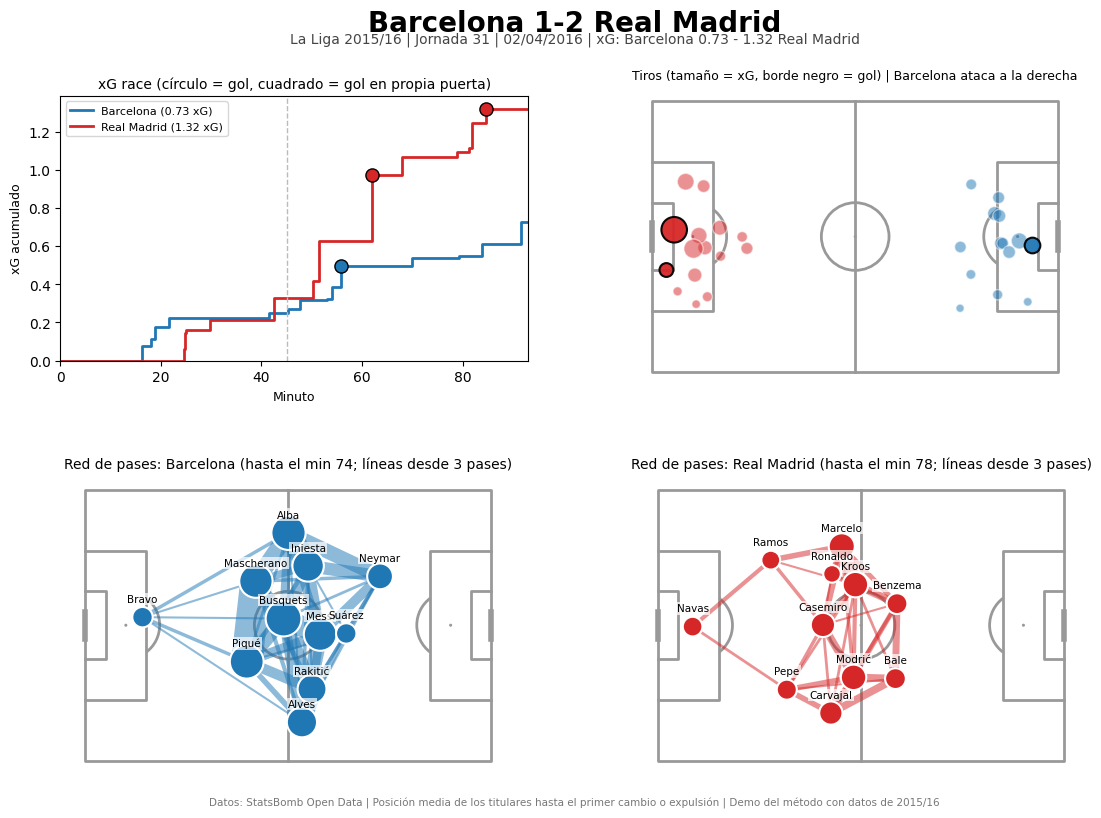

In [22]:
informe_partido(267533)   #el id hay que poner el partido que queramos ver